# Time-series templates

Most sncosmo sources are **time series**: a spectral template $F(p, \lambda)$ scaled by an amplitude, e.g. `"hsiao"`
(SN Ia), `"nugent-sn2p"` (SN II-P), or the SNANA core-collapse templates. {func}`saltjax.fit_lc` fits any
`sncosmo.TimeSeriesSource` as it fits SALT sources: same lightcurve tables, **same effects**, only the source changes:

```python
saltjax.fit_lc(data, targets, source="nugent-sn2p",
                       effects=[sncosmo.CCM89Dust(), sncosmo.CCM89Dust()],
                       effect_names=["mw", "host"], effect_frames=["obs", "rest"])
```

It fits $t_0$ and the amplitude, gives the same model, $\chi^2$ and errors as `sncosmo.fit_lc` (see
{doc}`../how_it_works`), and is much faster. This notebook:

1. loads and plots templates,
2. simulates SNe II-P with Milky Way and host dust,
3. fits them with and without host dust,
4. compares with `sncosmo.fit_lc`,
5. measures the speed.

In [1]:
import time, warnings
import numpy as np
import pandas
import matplotlib.pyplot as plt
import sncosmo
import saltjax
from saltjax.timeseries import TimeSeriesTemplate

warnings.filterwarnings("ignore", category=RuntimeWarning)
rng = np.random.default_rng(4)

## Templates

{class}`~saltjax.timeseries.TimeSeriesTemplate` wraps the spline of an `sncosmo.TimeSeriesSource`. Load it by name
(or from a source instance with `from_source`), and look at it:

TimeSeriesTemplate hsiao: phase -20 to 85 days (spline degree 3), wavelength 1000 to 25000 A
TimeSeriesTemplate nugent-sn2p: phase 0 to 411 days (spline degree 1), wavelength 1000 to 25000 A


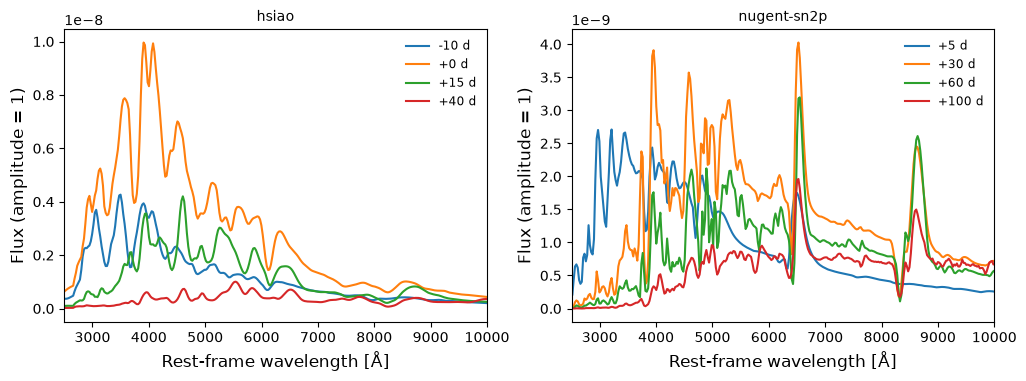

In [2]:
hsiao = TimeSeriesTemplate.from_name("hsiao")
sn2p = TimeSeriesTemplate.from_name("nugent-sn2p")
print(hsiao)
print(sn2p)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.8))
hsiao.show(ax=ax1, phases=[-10, 0, 15, 40])
sn2p.show(ax=ax2, phases=[5, 30, 60, 100])
for ax in (ax1, ax2):
    ax.set_xlim(2500, 10000)

`nugent-sn2p` is linear in time (spline degree 1) while `hsiao` is cubic: saltjax uses the same spline as sncosmo
in both cases. Outside its phase range, a template keeps its edge values, as in sncosmo.

## Simulate SNe II-P with Milky Way and host dust

We draw 300 SNe II-P between $z=0.005$ and $0.03$, with Milky Way dust (CCM89, observer frame) and host dust (CCM89,
rest frame) with an exponential $E(B-V)$ and an $R_V$ that varies from host to host. Each SN is observed in ZTF $g$,
$r$, $i$ every 2 to 4 days, with noise. The true model is an `sncosmo.Model` with both effects.

In [3]:
NSN = 300
DUST = dict(effects=[sncosmo.CCM89Dust(), sncosmo.CCM89Dust()],
            effect_names=["mw", "host"], effect_frames=["obs", "rest"])

targets = pandas.DataFrame({"z": rng.uniform(0.005, 0.03, NSN),
                            "t0": rng.uniform(59_000, 59_200, NSN),
                            "mwebv": rng.uniform(0, 0.15, NSN),
                            "hostebv": rng.exponential(0.1, NSN),
                            "hostr_v": rng.uniform(2.0, 4.0, NSN)},
                           index=pandas.Index(np.arange(NSN), name="index"))

lightcurves = []
for index_, row in targets.iterrows():
    model = sncosmo.Model(sn2p.source, **DUST)
    model.set(z=row["z"], t0=row["t0"], mwebv=row["mwebv"], hostebv=row["hostebv"], hostr_v=row["hostr_v"])
    model.set_source_peakabsmag(rng.normal(-17, 0.8), "bessellr", "ab")
    targets.loc[index_, "amplitude"] = model.get("amplitude")

    time_ = np.cumsum(rng.uniform(2, 4, 60)) + row["t0"] - 10       # from -10 to ~+170 days
    band = rng.choice(["ztfg", "ztfr", "ztfi"], len(time_))
    flux = np.array([model.bandflux(b_, t_, zp=25., zpsys="ab") for b_, t_ in zip(band, time_)])
    fluxerr = np.sqrt(np.abs(flux) * 2 + 15. ** 2)                    # photon + sky noise
    lightcurves.append(pandas.DataFrame({"time": time_, "band": band, "zp": 25., "zpsys": "ab",
                                         "flux": flux + rng.normal(0, fluxerr), "fluxerr": fluxerr}))

data = pandas.concat(lightcurves, keys=targets.index, names=["index", "index_obs"])
data.head()

time  band    zp zpsys       flux    fluxerr
index index_obs                                                      
0     0          59089.195180  ztfr  25.0    ab  26.260163  15.000000
      1          59092.786684  ztfi  25.0    ab -18.339273  15.000000
      2          59095.616972  ztfr  25.0    ab  -2.737408  15.000000
      3          59097.826562  ztfr  25.0    ab  41.554126  15.738715
      4          59101.136057  ztfg  25.0    ab  66.411857  17.535528

## Fit, with and without host dust

The parameters of the effects are read **per target** from the columns `{name}{param}` of `targets`: here `mwebv`,
`hostebv` and `hostr_v` (`mwr_v` is not given, so the effect instance value, 3.1, is used).

In [4]:
results = saltjax.fit_lc(data, targets, source=sn2p, **DUST)
results[["t0", "amplitude", "t0_err", "amplitude_err", "mwebv", "hostebv", "hostr_v", "chi2", "ndof"]].head()

/Users/rigault/libraries/saltjax/src/saltjax/timeseries.py:1063: UserWarning: 6 targets without data or detection are not fitted
  warnings.warn(f"{np.sum(~detected)} targets without data or detection are not fitted")


,t0,amplitude,t0_err,amplitude_err,mwebv,hostebv,hostr_v,chi2,ndof
index,,,,,,,,,
0,59095.270344,6.402678e-08,0.443857,1.905770e-09,0.011108,0.446599,3.138122,54.154162,58.0
1,59178.042156,1.377299e-07,0.156730,1.660791e-09,0.051067,0.136133,2.366487,45.878031,58.0
2,59104.691023,3.428349e-08,0.523314,9.349881e-10,0.029831,0.112417,2.956738,58.809770,58.0
3,59041.124630,4.051862e-07,0.116284,3.957249e-09,0.068760,0.382639,3.017158,66.510177,58.0
4,59197.102006,8.656465e-08,0.231563,1.239981e-09,0.090676,0.039861,2.414124,68.346773,58.0


By default, `fit_lc` only applies the Milky Way dust of the `mwebv` column. Host dust then dims the SN, and
the fitted amplitude absorbs it: it is biased low, by about $10^{-0.4 A_\mathrm{host}}$.

/Users/rigault/libraries/saltjax/src/saltjax/timeseries.py:1063: UserWarning: 6 targets without data or detection are not fitted
  warnings.warn(f"{np.sum(~detected)} targets without data or detection are not fitted")


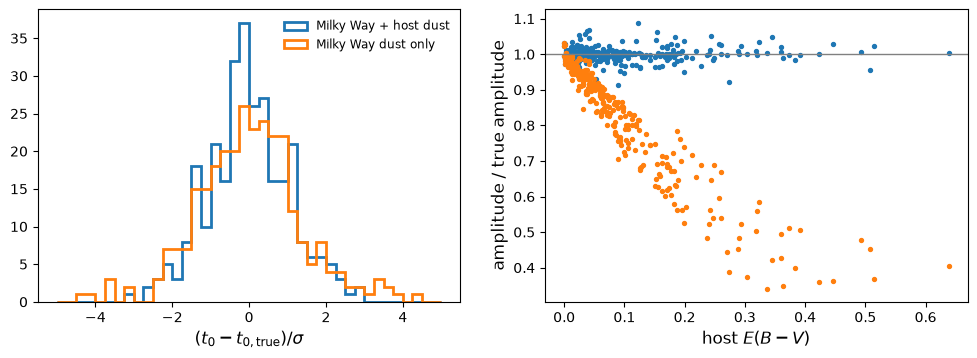

In [5]:
results_mw = saltjax.fit_lc(data, targets, source=sn2p)    # Milky Way dust only

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for res, label in [(results, "Milky Way + host dust"), (results_mw, "Milky Way dust only")]:
    pull_t0 = (res["t0"] - targets["t0"]) / res["t0_err"]
    ratio = res["amplitude"] / targets["amplitude"]
    axes[0].hist(pull_t0, bins=np.linspace(-5, 5, 41), histtype="step", lw=2, label=label)
    axes[1].scatter(targets["hostebv"], ratio, s=8, label=label)

axes[0].set_xlabel("$(t_0 - t_{0,\\mathrm{true}}) / \\sigma$", fontsize="large")
axes[1].set_xlabel("host $E(B-V)$", fontsize="large")
axes[1].set_ylabel("amplitude / true amplitude", fontsize="large")
axes[1].axhline(1, color="0.5", lw=1)
axes[0].legend(fontsize="small", frameon=False)

With the host dust given, $t_0$ pulls are standard normal and the amplitude is unbiased whatever the host
$E(B-V)$. Check any fit by eye with {meth}`~saltjax.timeseries.TimeSeriesTemplate.show_fit`, with the same effects as the fit:

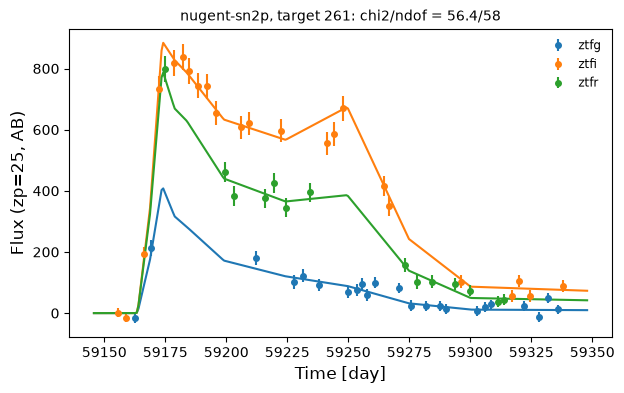

In [6]:
fig = sn2p.show_fit(data, results, index=results["hostebv"].idxmax(), **DUST)   # the most reddened SN

`show_fit` takes the same effects as the fit and reads their parameters (here `mwebv`, `hostebv`, `hostr_v`)
from `results`, so the curves are the fitted model.

## Comparison with sncosmo

`sncosmo.fit_lc` on 30 of these SNe, with the same model (template and both effects), started at the truth:

In [7]:
def fit_lc(index_):
    row, lc = targets.loc[index_], data.xs(index_)
    model = sncosmo.Model(sn2p.source, **DUST)
    model.set(z=row["z"], t0=row["t0"], amplitude=row["amplitude"], mwebv=row["mwebv"],
              hostebv=row["hostebv"], hostr_v=row["hostr_v"])
    res, _ = sncosmo.fit_lc({k: lc[k].to_numpy() for k in ["time", "band", "flux", "fluxerr", "zp", "zpsys"]},
                            model, ["t0", "amplitude"], bounds={"t0": (row["t0"] - 20, row["t0"] + 20)})
    return {"t0": res.parameters[1], "amplitude": res.parameters[2],
            "t0_err": res.errors["t0"], "amplitude_err": res.errors["amplitude"], "chi2": res.chisq}

subset = results.index[:30]
t = time.perf_counter()
sncosmo_results = pandas.DataFrame({index_: fit_lc(index_) for index_ in subset}).T
sncosmo_time = (time.perf_counter() - t) / len(subset)

comparison = pandas.DataFrame({
    f"{param_} diff / sigma": (results.loc[subset, param_] - sncosmo_results[param_]) / sncosmo_results[f"{param_}_err"]
    for param_ in ["t0", "amplitude"]} | {
    f"{param_}_err ratio": results.loc[subset, f"{param_}_err"] / sncosmo_results[f"{param_}_err"]
    for param_ in ["t0", "amplitude"]} | {
    "chi2 diff": results.loc[subset, "chi2"] - sncosmo_results["chi2"]})
comparison.describe().loc[["mean", "std", "min", "max"]]

,t0 diff / sigma,amplitude diff / sigma,t0_err ratio,amplitude_err ratio,chi2 diff
mean,0.000317,-0.000239,1.186739,1.000046,-1.022192e-05
std,0.002078,0.002500,1.022529,0.000258,1.700703e-05
min,-0.005262,-0.007782,0.999970,0.999920,-6.074786e-05
max,0.005830,0.005133,6.600672,1.001409,5.450489e-07


The fitted parameters agree to a small fraction of their error (the remaining differences are the convergence tolerance of Minuit), and the $\chi^2$ are the same, although saltjax starts from the data (a scan putting the highest S/N point at every phase of the template) while sncosmo starts here from the truth. The errors agree too, but for one SN, whose $t_0$ error is 6.6 times smaller with sncosmo.

### A note on templates linear in time

`nugent-sn2p` is linear in time, so the model flux of each point has a kink at each phase node of the template (every day, and a strong one at the explosion, phase 0). saltjax uses the exact curvature of the $\chi^2$ at the minimum, while Minuit (in sncosmo) uses finite differences: when a point sits next to a kink, they can pick up a curvature that is not there. The $\Delta\chi^2 = 1$ interval of the $\chi^2$ profile tells which error is right:

Delta chi2 = 1 half-width: 0.312 d


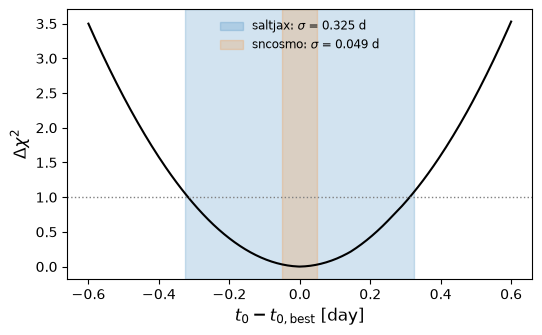

In [8]:
worst = comparison["t0_err ratio"].idxmax()
row, lc = targets.loc[worst], data.xs(worst)
model = sncosmo.Model(sn2p.source, **DUST)
model.set(z=row["z"], mwebv=row["mwebv"], hostebv=row["hostebv"], hostr_v=row["hostr_v"])

def chi2_profile(t0):
    """chi2 at t0, the amplitude being solved linearly"""
    model.set(t0=t0, amplitude=1.)
    flux_model = np.array([model.bandflux(b_, t_, zp=25., zpsys="ab") for b_, t_ in zip(lc["band"], lc["time"])])
    weight = 1 / lc["fluxerr"].to_numpy() ** 2
    amplitude = np.sum(weight * flux_model * lc["flux"]) / np.sum(weight * flux_model ** 2)
    return np.sum(weight * (lc["flux"] - amplitude * flux_model) ** 2)

t0_grid = results.loc[worst, "t0"] + np.linspace(-0.6, 0.6, 241)
dchi2 = np.array([chi2_profile(t0_) for t0_ in t0_grid])
dchi2 -= dchi2.min()
half_width = np.ptp(t0_grid[dchi2 <= 1]) / 2

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(t0_grid - results.loc[worst, "t0"], dchi2, color="k")
ax.axhline(1, color="0.5", lw=1, ls=":")
for err_, label, color in [(results.loc[worst, "t0_err"], "saltjax", "C0"),
                           (sncosmo_results.loc[worst, "t0_err"], "sncosmo", "C1")]:
    ax.axvspan(-err_, err_, color=color, alpha=0.2, label=f"{label}: $\\sigma$ = {err_:.3f} d")
ax.set_xlabel("$t_0 - t_{0,\\mathrm{best}}$ [day]", fontsize="large")
ax.set_ylabel("$\\Delta\\chi^2$", fontsize="large")
ax.legend(fontsize="small", frameon=False)
print(f"Delta chi2 = 1 half-width: {half_width:.3f} d")

The $\Delta\chi^2 = 1$ interval matches the saltjax error: here, Minuit underestimates the error. For templates that are smooth in time (e.g. `hsiao`, cubic), both agree.

## Speed

One call for the 300 SNe (the first call of a session includes compilation; later calls reuse it):

In [9]:
t = time.perf_counter()
saltjax.fit_lc(data, targets, source=sn2p, **DUST)
later = time.perf_counter() - t

print(f"saltjax: {later / NSN * 1e3:.2f} ms per SN | sncosmo.fit_lc: {sncosmo_time * 1e3:.1f} ms per SN "
      f"-> {sncosmo_time / (later / NSN):.0f} times faster")

saltjax: 0.58 ms per SN | sncosmo.fit_lc: 23.3 ms per SN -> 40 times faster


/Users/rigault/libraries/saltjax/src/saltjax/timeseries.py:1063: UserWarning: 6 targets without data or detection are not fitted
  warnings.warn(f"{np.sum(~detected)} targets without data or detection are not fitted")
